# CuPy reductions and prefix scans: numerical integration

This notebook is the CuPy counterpart of the PyCUDA integration notebook. It uses the **same function, midpoint grid, double precision, refinement sizes, validation tolerances, and plot styles**.

From the same local contributions for $f(x)=x^2$ on $[0,1]$, `cp.sum` produces the definite integral and `cp.cumsum` produces cumulative integrals. An optional `cp.ReductionKernel` combines contribution evaluation and reduction.

The elementary midpoint rule keeps the focus on library interfaces. The book's PyCUDA section develops its mathematical interpretation; this standalone notebook retains short reminders for running the experiment independently. Efficient reductions and scans are supplied by the library.

Run the cells in order in a Colab GPU runtime. Printouts and plots appear directly in cells. No figures, spreadsheets, or result files are exported. These are correctness and quadrature-convergence experiments, not speed benchmarks.

## 1. Prepare the GPU runtime

In Google Colab select **Runtime → Change runtime type → GPU** and connect. `nvidia-smi` checks the GPU; its CUDA version describes driver support. `nvcc --version` identifies the toolkit used to select an installation package if necessary. CuPy manages runtime compilation internally; no PyCUDA installation is required.

In [1]:
!nvidia-smi
!nvcc --version

Sun Oct 18 06:03:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Use the existing CuPy installation when available. The next cell installs a CUDA-specific binary package **only if CuPy is absent**, selecting CUDA 12 or 13 from the installed toolkit. It does not install PyCUDA or a notebook extension. Do not install multiple CuPy packages in the same environment.

If an existing CuPy installation fails to import, use a fresh Colab GPU runtime before proceeding. For other environments, follow the [CuPy installation guide](https://docs.cupy.dev/en/stable/install.html).

In [2]:
import importlib.util
import re
import subprocess
import sys

if importlib.util.find_spec("cupy") is None:
    toolkit_info = subprocess.check_output(
        ["nvcc", "--version"], text=True
    )
    match = re.search(r"release\s+(\d+)\.", toolkit_info)
    if match is None or int(match.group(1)) not in (12, 13):
        raise RuntimeError("Use a Colab GPU runtime with CUDA 12 or 13, or follow the CuPy installation guide.")
    package = f"cupy-cuda{match.group(1)}x"
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])
    print("Installed:", package)
else:
    print("Using the existing CuPy installation.")

Using the existing CuPy installation.


## 2. Import the libraries

The main operations are `cp.sum` and `cp.cumsum`. An optional final cell uses `cp.ReductionKernel` for a custom mapping before summation.

Use `float64`, matching the PyCUDA integration example. Double precision helps separate quadrature error from roundoff under refinement; it is not a performance recommendation.

In [3]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("Select a GPU runtime in Colab.")
cp.cuda.Device(0).use()
device_name = cp.cuda.runtime.getDeviceProperties(0)["name"]
if isinstance(device_name, bytes):
    device_name = device_name.decode()
DTYPE = np.float64
RTOL = 5e-12
ATOL = 5e-14

print('GPU:', device_name)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('CuPy:', cp.__version__)
print('Integration dtype:', np.dtype(DTYPE))
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

GPU: Tesla T4
Python: 3.13.15
NumPy: 2.1.3
CuPy: 14.0.1
Integration dtype: float64


## 3. Define the midpoint contributions

Let $x_j=jh$ with $h=1/N$ and $j=0,\ldots,N$. Each subinterval contributes

$$w_i=h\,f((i+1/2)h)=h((i+1/2)h)^2,\qquad i=0,\ldots,N-1.$$

These values approximate **local areas**, not just function samples. Including the factor $h$ is essential. Their sum approximates the whole integral; their cumulative sums approximate the integral up to successive right endpoints.

The short helper below constructs only the grid. Evaluation of the contributions used by the main calculation takes place on the GPU.


In [4]:
def midpoint_grid(n):
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError('n must be a positive integer.')
    h = DTYPE(1.0 / int(n))
    midpoints = (np.arange(n, dtype=DTYPE) + DTYPE(0.5)) * h
    endpoints = np.arange(n + 1, dtype=DTYPE) * h
    return h, midpoints, endpoints

N = 256
h, h_midpoints, h_endpoints = midpoint_grid(N)
print(f'Subintervals: {N}; width h: {h:g}')
print('Exact definite integral: 1/3')


Subintervals: 256; width h: 0.00390625
Exact definite integral: 1/3


## 4. Visualize the deliberately simple quadrature

A coarse eight-subinterval illustration makes the midpoint rectangles visible. It explains the rule; the main GPU calculation uses `N` defined above. This figure is constructed from the analytical function, not from GPU measurements.


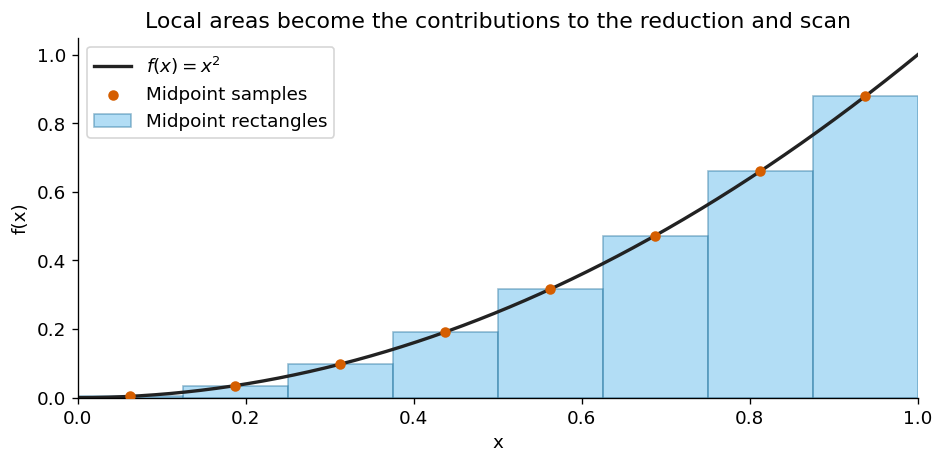

In [5]:
N_VIS = 8
h_vis, mid_vis, edges_vis = midpoint_grid(N_VIS)
x_dense = np.linspace(0.0, 1.0, 600)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(mid_vis, mid_vis**2, width=float(h_vis), align='center',
       color='#56B4E9', edgecolor='#24729B', alpha=0.45,
       label='Midpoint rectangles')
ax.plot(x_dense, x_dense**2, color='#222222', lw=2, label=r'$f(x)=x^2$')
ax.scatter(mid_vis, mid_vis**2, color='#D55E00', s=28, zorder=3,
           label='Midpoint samples')
ax.set(xlabel='x', ylabel='f(x)', xlim=(0, 1), ylim=(0, 1.05),
       title='Local areas become the contributions to the reduction and scan')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()


## 5. Build the contribution array on the GPU

Transfer midpoint coordinates using `cp.asarray`, then evaluate local areas with CuPy arithmetic. Both reduction and scan use the same `d_weights` array. The factor `h` converts function values to midpoint area contributions.

An independent NumPy expression checks contribution construction. The CPU sum and cumulative sum then use a retrieved copy of the actual stored GPU contributions. This separates the check of contribution evaluation from the check of their aggregation. These extra transfers are for validation; they are not required to compute the GPU integral.

In [6]:
d_midpoints = cp.asarray(h_midpoints)
d_weights = (d_midpoints * d_midpoints) * h
h_weights = cp.asnumpy(d_weights)
h_weights_reference = (h_midpoints * h_midpoints) * h
assert np.all(np.isfinite(h_weights))
np.testing.assert_allclose(h_weights, h_weights_reference, rtol=RTOL, atol=ATOL)

I_cpu = np.sum(h_weights, dtype=DTYPE)
F_cpu = np.concatenate(([DTYPE(0)], np.cumsum(h_weights, dtype=DTYPE)))
print('GPU contribution array validated against NumPy.')
print('First five local areas:', h_weights[:5])

GPU contribution array validated against NumPy.
First five local areas: [1.49011612e-08 1.34110451e-07 3.72529030e-07 7.30156898e-07
 1.20699406e-06]


## 6. Reduction: one integral over the whole interval

`cp.sum` combines the local areas and returns a zero-dimensional CuPy array stored on the GPU. `cp.asnumpy(...).item()` retrieves its value for printing and checking. Accumulation uses `float64` explicitly.

The difference from the NumPy sum checks the discrete computation. The difference from the exact integral $1/3$ includes quadrature error; a correct implementation does not make that error disappear.

In [7]:
d_integral = cp.sum(d_weights, dtype=DTYPE)
I_gpu = DTYPE(cp.asnumpy(d_integral).item())
assert np.isfinite(I_gpu)
np.testing.assert_allclose(I_gpu, I_cpu, rtol=RTOL, atol=ATOL)

I_exact = DTYPE(1.0 / 3.0)
print(f'GPU midpoint integral:      {I_gpu:.16f}')
print(f'NumPy midpoint integral:    {I_cpu:.16f}')
print(f'Exact integral, 1/3:        {I_exact:.16f}')
print(f'GPU vs NumPy difference:    {abs(I_gpu - I_cpu):.3e}')
print(f'Error vs exact integral:    {abs(I_gpu - I_exact):.3e}')

GPU midpoint integral:      0.3333320617675781
NumPy midpoint integral:    0.3333320617675781
Exact integral, 1/3:        0.3333333333333333
GPU vs NumPy difference:    0.000e+00
Error vs exact integral:    1.272e-06


## 7. Inclusive prefix scan: integrals up to all endpoints

`cp.cumsum` performs the inclusive cumulative sum. Without an `out` argument it returns a new array and preserves `d_weights`. Unlike the PyCUDA `InclusiveScanKernel` invocation in the companion notebook, no preliminary input copy or scan-kernel definition is needed here.

The output contains $F_1,\ldots,F_N$, corresponding to the **right endpoints** of successive subintervals. Prepending $F_0=0$ after retrieval aligns the results with `h_endpoints`, not with midpoint coordinates. The result approximates $\int_0^x t^2\,dt$ with the constant fixed by $F(0)=0$; it is not symbolic indefinite integration.

The last prefix and the reduction represent the same discrete sum, but different floating-point evaluation orders can produce small differences. We compare with tolerances.

In [8]:
d_prefix = cp.cumsum(d_weights, dtype=DTYPE)
h_prefix = cp.asnumpy(d_prefix)
np.testing.assert_array_equal(cp.asnumpy(d_weights), h_weights)
F_gpu = np.concatenate(([DTYPE(0)], h_prefix))
F_exact = h_endpoints**3 / DTYPE(3)

assert np.all(np.isfinite(F_gpu))
np.testing.assert_allclose(F_gpu, F_cpu, rtol=RTOL, atol=ATOL)
np.testing.assert_allclose(F_gpu[-1], I_gpu, rtol=RTOL, atol=ATOL)
print(f'All {N + 1} cumulative values validated against NumPy.')
print(f'Largest GPU vs NumPy difference: {np.max(np.abs(F_gpu - F_cpu)):.3e}')
print(f'Largest error vs x^3/3:          {np.max(np.abs(F_gpu - F_exact)):.3e}')
print(f'Final prefix vs reduction:       {abs(F_gpu[-1] - I_gpu):.3e}')

selected = np.unique(np.linspace(0, N, min(N + 1, 9), dtype=int))
print(f"{'j':>7} {'x_j':>11} {'F_j (GPU)':>18} {'x_j^3/3':>18} {'abs. error':>14}")
for j in selected:
    print(f'{j:7d} {h_endpoints[j]:11.6f} {F_gpu[j]:18.12f} '
          f'{F_exact[j]:18.12f} {abs(F_gpu[j] - F_exact[j]):14.3e}')

All 257 cumulative values validated against NumPy.
Largest GPU vs NumPy difference: 0.000e+00
Largest error vs x^3/3:          1.272e-06
Final prefix vs reduction:       0.000e+00
      j         x_j          F_j (GPU)            x_j^3/3     abs. error
      0    0.000000     0.000000000000     0.000000000000      0.000e+00
     32    0.125000     0.000650882721     0.000651041667      1.589e-07
     64    0.250000     0.005208015442     0.005208333333      3.179e-07
     96    0.375000     0.017577648163     0.017578125000      4.768e-07
    128    0.500000     0.041666030884     0.041666666667      6.358e-07
    160    0.625000     0.081379413605     0.081380208333      7.947e-07
    192    0.750000     0.140624046326     0.140625000000      9.537e-07
    224    0.875000     0.223306179047     0.223307291667      1.113e-06
    256    1.000000     0.333332061768     0.333333333333      1.272e-06


## 8. Plot the cumulative integral and its error

The left plot compares the actual scan result with $x^3/3$ and marks the reduction at $x=1$. The curves can nearly coincide, so the right plot displays the signed integration error separately.

For this particular function, the midpoint rule has the exact-arithmetic error

$$F_j-\frac{x_j^3}{3}=-\frac{x_jh^2}{12},\qquad I_N-\frac13=-\frac{1}{12N^2}.$$

This known quadrature error is an additional reference. It is distinct from the small discrepancies caused by floating-point summation.


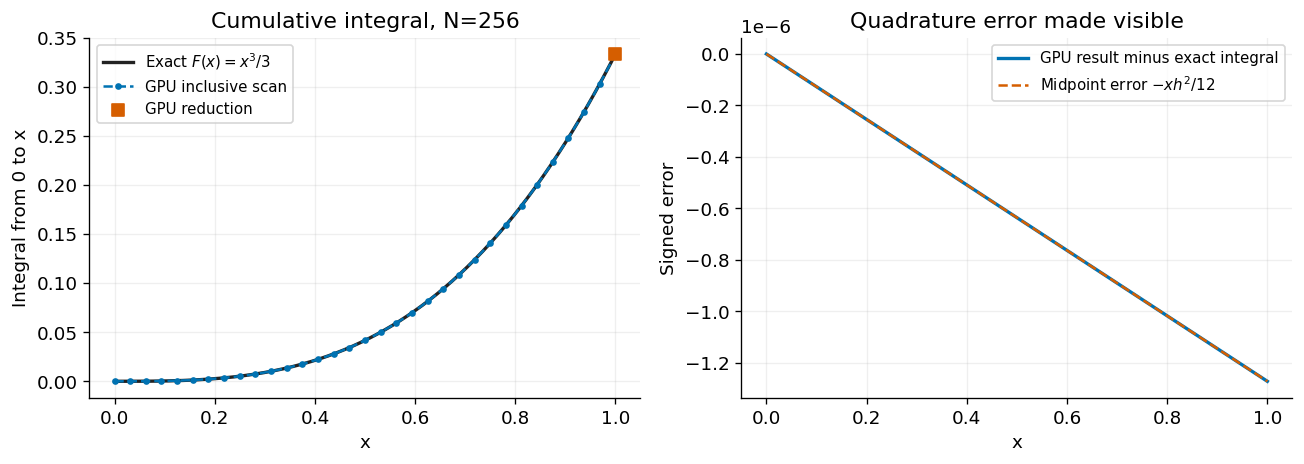

In [9]:
expected_signed_error = -h_endpoints * h**2 / DTYPE(12)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x_dense, x_dense**3 / 3.0, color='#222222', lw=2,
             label=r'Exact $F(x)=x^3/3$')
stride = max(1, N // 32)
axes[0].plot(h_endpoints, F_gpu, color='#0072B2', linestyle='--',
             marker='o', markersize=3, markevery=stride, label='GPU inclusive scan')
axes[0].scatter([1.0], [I_gpu], color='#D55E00', marker='s', s=45,
                zorder=4, label='GPU reduction')
axes[0].set(xlabel='x', ylabel='Integral from 0 to x', title=f'Cumulative integral, N={N}')
axes[0].legend(fontsize=9)
axes[1].plot(h_endpoints, F_gpu - F_exact, color='#0072B2', lw=2,
             label='GPU result minus exact integral')
axes[1].plot(h_endpoints, expected_signed_error, '--', color='#D55E00',
             label=r'Midpoint error $-xh^2/12$')
axes[1].set(xlabel='x', ylabel='Signed error', title='Quadrature error made visible')
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes[1].legend(fontsize=9)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## 9. Refine the grid and separate the two sources of error

Repeat both GPU operations for several lengths, including 257 to avoid testing only powers of two. Each run checks every cumulative value against NumPy. The table distinguishes errors relative to the analytical integral from differences relative to the same discrete CPU sum.

For this smooth quadratic example, midpoint quadrature errors decrease proportionally to `1/N**2` until roundoff becomes significant. This verifies the integration rule; it is not a speed benchmark. These modest problem sizes are chosen for teaching, not to demonstrate a GPU speedup.


In [10]:
def integration_errors(n):
    step, mid, edges = midpoint_grid(n)
    coords_gpu = cp.asarray(mid)
    weights_gpu = (coords_gpu * coords_gpu) * step
    weights_host = cp.asnumpy(weights_gpu)
    np.testing.assert_allclose(weights_host, (mid * mid) * step,
                               rtol=RTOL, atol=ATOL)
    total_gpu = cp.sum(weights_gpu, dtype=DTYPE)
    total = DTYPE(cp.asnumpy(total_gpu).item())
    prefix_gpu = cp.cumsum(weights_gpu, dtype=DTYPE)
    cumulative = np.concatenate(([DTYPE(0)], cp.asnumpy(prefix_gpu)))
    cpu_total = np.sum(weights_host, dtype=DTYPE)
    cpu_cumulative = np.concatenate(([DTYPE(0)], np.cumsum(weights_host, dtype=DTYPE)))
    assert np.isfinite(total) and np.all(np.isfinite(cumulative))
    np.testing.assert_allclose(total, cpu_total, rtol=RTOL, atol=ATOL)
    np.testing.assert_allclose(cumulative, cpu_cumulative, rtol=RTOL, atol=ATOL)
    np.testing.assert_allclose(cumulative[-1], total, rtol=RTOL, atol=ATOL)
    return (abs(total - 1.0 / 3.0),
            np.max(np.abs(cumulative - edges**3 / 3.0)),
            abs(total - cpu_total),
            np.max(np.abs(cumulative - cpu_cumulative)))

sizes = np.array([8, 16, 32, 64, 128, 257, 512, 1024, 2048, 4096, 8192])
errors = np.array([integration_errors(int(n)) for n in sizes])
print(f"{'N':>7} {'reduction vs exact':>20} {'scan vs exact (max)':>22} "
      f"{'reduction vs CPU':>19} {'scan vs CPU (max)':>20}")
for n, row in zip(sizes, errors):
    print(f'{n:7d} {row[0]:20.3e} {row[1]:22.3e} {row[2]:19.3e} {row[3]:20.3e}')
print('All GPU reductions and scans passed their discrete NumPy checks.')

      N   reduction vs exact    scan vs exact (max)    reduction vs CPU    scan vs CPU (max)
      8            1.302e-03              1.302e-03           0.000e+00            0.000e+00
     16            3.255e-04              3.255e-04           0.000e+00            0.000e+00
     32            8.138e-05              8.138e-05           0.000e+00            0.000e+00
     64            2.035e-05              2.035e-05           0.000e+00            0.000e+00
    128            5.086e-06              5.086e-06           0.000e+00            0.000e+00
    257            1.262e-06              1.262e-06           0.000e+00            5.551e-17
    512            3.179e-07              3.179e-07           0.000e+00            0.000e+00
   1024            7.947e-08              7.947e-08           0.000e+00            0.000e+00
   2048            1.987e-08              1.987e-08           0.000e+00            0.000e+00
   4096            4.967e-09              4.967e-09           0.000e+0

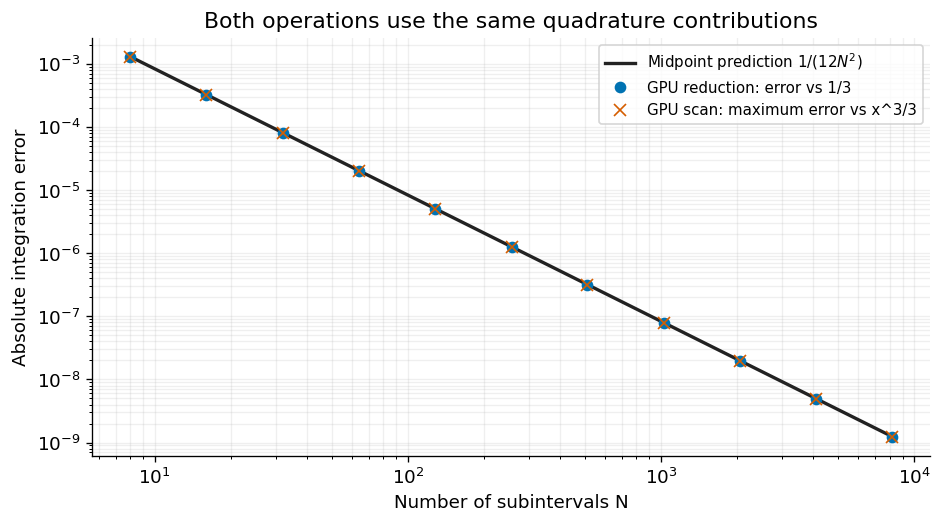

In [11]:
theoretical_error = 1.0 / (12.0 * sizes.astype(np.float64)**2)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(sizes, theoretical_error, color='#222222', lw=2,
          label=r'Midpoint prediction $1/(12N^2)$')
ax.loglog(sizes, errors[:, 0], 'o', color='#0072B2', markersize=6,
          label='GPU reduction: error vs 1/3')
ax.loglog(sizes, errors[:, 1], 'x', color='#D55E00', markersize=7,
          label='GPU scan: maximum error vs x^3/3')
ax.set(xlabel='Number of subintervals N', ylabel='Absolute integration error',
       title='Both operations use the same quadrature contributions')
ax.grid(which='both', alpha=0.2)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


## 10. Optional: a custom contribution with ReductionKernel

`cp.sum` suffices when the contribution array is already available. `cp.ReductionKernel` also accepts an input-to-contribution mapping and its reduction. Here it evaluates `(x*x)*h` from each midpoint coordinate and sums those values, without constructing a separate full contribution array in the calling code.

CuPy separates input and output declarations. The mapping uses current element values; the reduction expression combines partial results named `a` and `b`; the final mapping writes the result to `total`. Zero is the identity for addition. This is a library-generated parallel reduction, not a hand-written reduction algorithm.

This optional route computes only the definite integral. The main scan still uses ordered local contributions. Internal implementation work/storage and floating-point evaluation order need not match the separate construction-plus-sum route; no timing advantage is claimed.

In [12]:
integrate_midpoints = cp.ReductionKernel(
    'float64 x, float64 h',
    'float64 total',
    '(x * x) * h',
    'a + b',
    'total = a',
    '0',
    'integrate_square_midpoints',
)
d_custom_integral = integrate_midpoints(d_midpoints, h)
I_custom = DTYPE(cp.asnumpy(d_custom_integral).item())
assert np.isfinite(I_custom)
np.testing.assert_allclose(I_custom, I_cpu, rtol=RTOL, atol=ATOL)
print(f'Custom mapped reduction: {I_custom:.16f}')
print(f'Difference from sum of stored contributions: {abs(I_custom - I_gpu):.3e}')
print(f'Error vs exact integral: {abs(I_custom - I_exact):.3e}')
del d_custom_integral

Custom mapped reduction: 0.3333320617675781
Difference from sum of stored contributions: 0.000e+00
Error vs exact integral: 1.272e-06


## 11. What changed from PyCUDA?

| Operation | PyCUDA notebook | CuPy notebook |
|---|---|---|
| Transfer coordinates | `gpuarray.to_gpu` | `cp.asarray` |
| Evaluate contributions | GPUArray arithmetic | CuPy array arithmetic |
| Definite integral | `gpuarray.sum` | `cp.sum` |
| Cumulative integrals | `InclusiveScanKernel` on a copy | `cp.cumsum` returning a new array |
| Custom contribution/reduction | `ReductionKernel` | `cp.ReductionKernel` with its own declaration syntax |
| Retrieve results | `.get()` | `cp.asnumpy` |

The mathematical method is unchanged. More advanced quadrature changes the local contribution construction; reduction and, where ordered local contributions are defined, scan remain the aggregation operations. Using a library primitive avoids implementing its parallel coordination ourselves.

The default grid and all refinement sizes match the PyCUDA experiment. The plots show quadrature accuracy, not performance differences between the libraries. NumPy checks compare the same discrete contributions, while analytical curves expose integration error.

**Preparation status:** outputs are cleared. Python syntax, matching numerical parameters, mathematical references, and CPU-side plot rendering were checked during preparation. CUDA execution was unavailable. Run the notebook on Colab to obtain actual GPU validation results and plots.

References: [cupy.sum](https://docs.cupy.dev/en/stable/reference/generated/cupy.sum.html), [cupy.cumsum](https://docs.cupy.dev/en/stable/reference/generated/cupy.cumsum.html), [ReductionKernel](https://docs.cupy.dev/en/stable/reference/generated/cupy.ReductionKernel.html).

## 12. Cleanup

After completing the examples, wait for pending work and remove the persistent device-array references. CuPy's memory pool may retain released storage for reuse. Restart from the contribution-construction cell to repeat the main computation.

In [13]:
cp.cuda.get_current_stream().synchronize()
del d_midpoints, d_weights, d_integral, d_prefix
print('Persistent GPU array references released.')

Persistent GPU array references released.
